# Week 10 · Statistics for data science

**CMT309/509 · CMT124** · shared session · Thursday 10 December 2026

In Week 5 you **described** data: means, medians, standard deviations. Today you learn to **reason** with data: how likely is an event, how sure can we be about a mean, and is a difference between two groups real or just noise?

By the end of today you can compute conditional probabilities and use Bayes' theorem, describe a random variable with its PMF, pdf or CDF and name the matching `scipy.stats` distribution, report an estimate **with a 95 % confidence interval**, and set up and read a two-sample t-test.

Today has two teaching parts and a lab: **Hour 1** probability and random variables · **Hour 2** from samples to conclusions · **Lab** an unfair die, then real CO₂ data.

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(10)      # seeded, so everyone sees the same random numbers

## Hour 1 · Probability and random variables

### From describing to modelling

Week 5's summaries describe **the data you have**. Probability describes **the process that produced it**: the die, the weather, the sampling of countries. Once we have a model of the process, we can ask how surprised we should be by the data.

**Quick check:** a week of rainfall has one very wet day. Which summary moves more, the mean or the median?

<details><summary>Answer</summary>

The **mean**: one extreme value pulls it, while the median only depends on the middle of the sorted values.

</details>

### Experiments, outcomes and events

Probability is a number between 0 and 1 that says how likely an **event** is in an **experiment**.

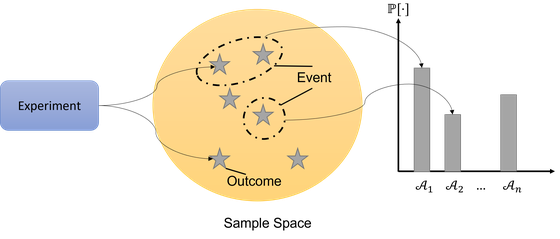

| Term | Symbol | Two coin tosses |
|---|---|---|
| sample space: every possible outcome | $\Omega$ | {HH, HT, TH, TT} |
| event: a subset of $\Omega$ | $A$ | "exactly one head" = {HT, TH} |
| event space: all the events | $\mathcal{F}$ | every subset of $\Omega$ |
| probability law | $\mathbb{P}: \mathcal{F} \to [0, 1]$ | $\mathbb{P}(A) = 2/4$ |

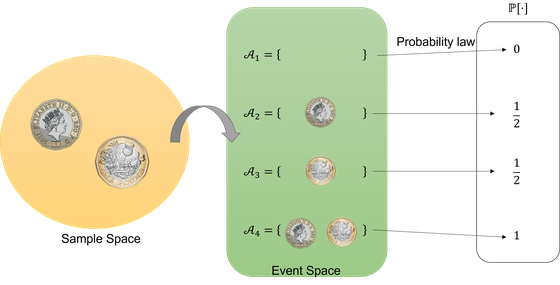

### Probability as a long-run frequency

**Predict:** toss a fair coin 10 times. Will exactly half be heads? And after 10,000 tosses?

In [ ]:
# ✍️ Type along: simulate coin tosses and die rolls, compare with 1/2 and 1/6
N = 10

<details><summary>Code from class</summary>

```python
N = 10
coin = rng.integers(0, 2, size=N)      # 1 = heads, 0 = tails
dice = rng.integers(1, 7, size=N)      # faces 1 to 6
print("P(heads) ~", coin.mean(), "  theory 0.5")
print("P(six)   ~", (dice == 6).mean(), "  theory", round(1 / 6, 3))
# now try N = 10_000
```

</details>

**Before we run this:** the line below shows the fraction of heads after each toss. Where will it start, and where will it end up?

In [ ]:
N = 5000
coin = rng.integers(0, 2, size=N)
running = coin.cumsum() / np.arange(1, N + 1)        # fraction of heads so far
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(np.arange(1, N + 1), running)
ax.axhline(0.5, ls="--", color="grey")
ax.set(xscale="log", xlabel="number of tosses (log scale)", ylabel="fraction of heads")
plt.show()

Early on the fraction jumps between 0 and 1; with more tosses it settles near 0.5. This is the **law of large numbers**: a long-run frequency approaches the probability. It never says "exactly half" for a finite number of tosses.

### Conditional probability and independence

The probability of $A$ **given** that $B$ has happened:

$$\mathbb{P}(A \mid B) = \frac{\mathbb{P}(A \cap B)}{\mathbb{P}(B)}$$

Roll two dice. $A$ = "the total is greater than 7", $B$ = "the total is even". There are 36 equally likely pairs (the totals 2 to 12 are **not** equally likely), so $\mathbb{P}(A) = 15/36$, $\mathbb{P}(B) = 18/36$, $\mathbb{P}(A \cap B) = 9/36$ and $\mathbb{P}(A \mid B) = 9/18 = 1/2$.

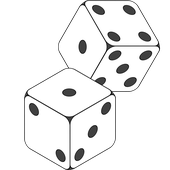

$A$ and $B$ are **independent** when knowing $B$ doesn't change the chance of $A$: $\mathbb{P}(A \mid B) = \mathbb{P}(A)$, or equivalently $\mathbb{P}(A \cap B) = \mathbb{P}(A)\,\mathbb{P}(B)$.

In [ ]:
# ✍️ Type along: estimate P(A | B) for two dice by simulation
N = 100_000
die1 = rng.integers(1, 7, size=N)
die2 = rng.integers(1, 7, size=N)

<details><summary>Code from class</summary>

```python
N = 100_000
die1 = rng.integers(1, 7, size=N)
die2 = rng.integers(1, 7, size=N)
total = die1 + die2
A = total > 7                      # Boolean masks (Week 5)
B = total % 2 == 0
print("P(A) ~", A.mean(), "  P(B) ~", B.mean(), "  P(A and B) ~", (A & B).mean())
print("P(A | B) ~", (A & B).mean() / B.mean())
print("same thing, by keeping only the rolls where B happened:", A[B].mean())
print("independent? compare P(A)P(B) =", A.mean() * B.mean())
```

</details>

$\mathbb{P}(A \mid B) \approx 0.50$ but $\mathbb{P}(A) \approx 0.42$: knowing the total is even **changes** the chance of a high total, so $A$ and $B$ are **not** independent. `A[B].mean()` shows the idea behind conditioning: throw away the rolls where $B$ didn't happen, then count.

**Your turn:** let $C$ = "the first die shows 5". Are $C$ and $B$ ("the total is even") independent? Estimate $\mathbb{P}(C)$, $\mathbb{P}(B)$ and $\mathbb{P}(C \cap B)$, and compare. Predict first!

In [ ]:
N = 100_000
die1 = rng.integers(1, 7, size=N)
die2 = rng.integers(1, 7, size=N)
B = (die1 + die2) % 2 == 0
# your code here

<details><summary>Answer</summary>

```python
C = die1 == 5
print(C.mean(), B.mean(), (C & B).mean(), C.mean() * B.mean())
# about 0.167  0.5  0.083  0.083
```

They **are** independent, which surprises most people. Whatever the first die shows, the second die makes the total even in exactly half of its outcomes. Compare $A$ = "total > 7" with $C$: there, $\mathbb{P}(A \mid C) = 4/6$, far from $\mathbb{P}(A)$.

</details>

### Bayes' theorem and the Monty Hall problem

Bayes' theorem turns $\mathbb{P}(B \mid A)$ into $\mathbb{P}(A \mid B)$. The bottom line comes from the **total probability** over the possible causes $A_1, \dots, A_n$:

$$\mathbb{P}(A_1 \mid B) = \frac{\mathbb{P}(B \mid A_1)\,\mathbb{P}(A_1)}{\mathbb{P}(B)}, \qquad \mathbb{P}(B) = \sum_{i=1}^{n} \mathbb{P}(B \mid A_i)\,\mathbb{P}(A_i)$$

A game show: a car is behind one of three doors, goats behind the other two. You pick door 1. The host, **who knows where the car is**, opens door 2 to show a goat, and offers you door 3.

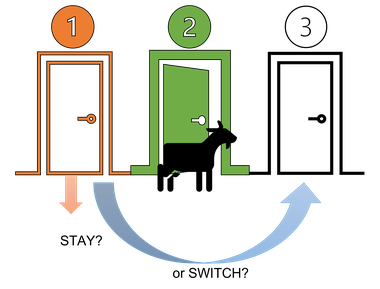

**Predict:** should you stay, switch, or does it not matter?

In [ ]:
n = 30_000
car = rng.integers(0, 3, size=n)      # the door hiding the car
pick = rng.integers(0, 3, size=n)     # your first choice
print("stay wins:  ", (pick == car).mean())
print("switch wins:", (pick != car).mean())

Why is "switch wins" simply `pick != car`? The host always opens a **goat** door you didn't pick, so the one remaining closed door hides the car exactly when your first pick was wrong, which happens 2 times in 3.

Bayes gives the same answer. With the car behind door $i$ ($\mathbb{P} = 1/3$ each), the chance that the host opens door 2 is $1/2$ (car behind 1: he picks 2 or 3 at random), $0$ (car behind 2) or $1$ (car behind 3: door 2 is his only option). So $\mathbb{P}(\text{opens } 2) = \tfrac13(\tfrac12 + 0 + 1) = \tfrac12$, and

$$\mathbb{P}(\text{car } 1 \mid \text{opens } 2) = \frac{\tfrac12 \cdot \tfrac13}{\tfrac12} = \frac13, \qquad \mathbb{P}(\text{car } 3 \mid \text{opens } 2) = \frac{1 \cdot \tfrac13}{\tfrac12} = \frac23.$$

### Random variables: PMF, CDF, expectation

A **random variable** $X$ turns outcomes into numbers: for a coin, $X(\text{heads}) = 1$, $X(\text{tails}) = 0$.

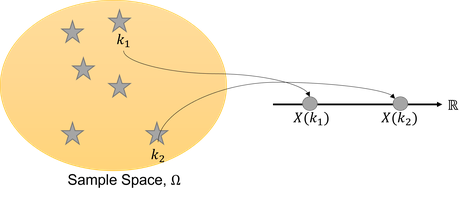

| | Discrete $X$ (a die) | Continuous $X$ (a temperature) |
|---|---|---|
| how likely each value is | **PMF** $p_X(a) = \mathbb{P}(X = a)$ | **pdf** $f_X(x)$: probability per unit length |
| **CDF** $F_X(x) = \mathbb{P}(X \le x)$ | $\sum_{a \le x} p_X(a)$ | $\int_{-\infty}^{x} f_X(t)\,dt$ |
| **expectation** $\mathbb{E}[X]$ | $\sum_a a\,p_X(a)$ | $\int x\,f_X(x)\,dx$ |

$\mathrm{Var}[X] = \mathbb{E}[(X - \mathbb{E}[X])^2]$. The expectation comes from the **model**; the average comes from **data**. They agree only in the long run.

A PMF is the **ideal histogram**: the histogram of infinitely many samples.

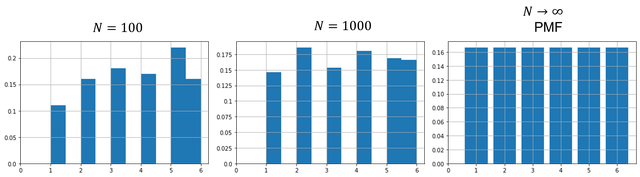

**Before we run this:** we roll a fair die 60 times. Will each face come up exactly 10 times? How close will the average be to $\mathbb{E}[X] = 3.5$?

In [ ]:
rolls = rng.integers(1, 7, size=60)
freq = [(rolls == face).mean() for face in range(1, 7)]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(range(1, 7), freq, alpha=0.7, label="histogram (relative frequency)")
ax.axhline(1 / 6, color="black", ls="--", label="PMF = 1/6")
ax.set(xlabel="face", ylabel="probability"); ax.legend(loc="lower right"); plt.show()
print("average of the rolls:", rolls.mean(), "   E[X] = 3.5")

With 60 rolls the bars are uneven and the average misses 3.5: the histogram is a **noisy estimate** of the PMF.

**Try it:** change `60` to `6000` and run again.

The die's CDF climbs in steps of 1/6, reaching 1 at face 6:

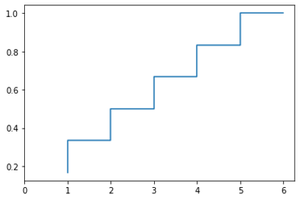

### What distributions look like

Many processes follow one of a few standard shapes. Four of them (Hour 2 adds their `scipy.stats` names):

<img alt="PMFs of the Bernoulli (p = 0.3), binomial (n = 5, p = 0.4) and Poisson (mean 0.6) distributions, and the standard Gaussian pdf" src="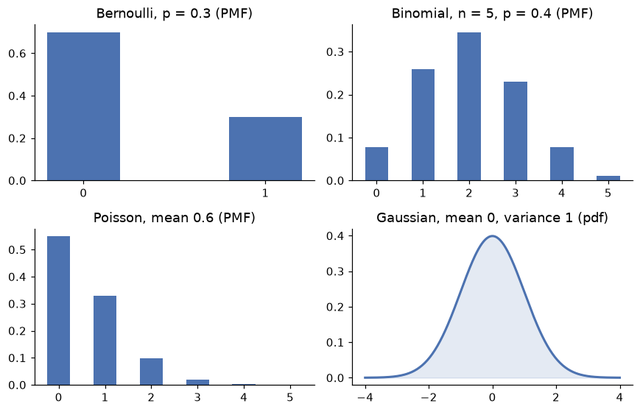">

| Distribution | Models |
|---|---|
| Bernoulli | one yes/no trial (rain today?) |
| Binomial | number of "yes" in $n$ independent trials |
| Poisson | number of events in a fixed time or area, at a constant average rate |
| Gaussian (normal) | sums of many small independent effects (measurement errors, heights) |

**Discuss:** which distribution would you use for the **number of flood warnings issued per month** in one river catchment? Which of its assumptions might fail?

<details><summary>Answer</summary>

A **Poisson** distribution: it counts events in a fixed period at an average rate. Its assumptions are that events are independent and the rate is constant. Flood warnings cluster in wet winters and storms trigger several at once, so real counts usually vary more than a Poisson predicts. The model is a sensible starting point, to be checked against data.

</details>

### Takeaways: probability and random variables

* A probability is a long-run frequency: simulations converge to it slowly (law of large numbers).
* $\mathbb{P}(A \mid B) = \mathbb{P}(A \cap B) / \mathbb{P}(B)$; independence means $\mathbb{P}(A \cap B) = \mathbb{P}(A)\,\mathbb{P}(B)$. Check, don't guess.
* Bayes' theorem reverses a conditional probability; in Monty Hall, switching wins 2/3 of the time.
* A random variable has a PMF (discrete) or pdf (continuous) and a CDF; the PMF is the ideal histogram, the expectation the ideal average.

## Hour 2 · From samples to conclusions

In Hour 1 we knew the model and simulated data. In practice it is the other way round: we **have data** and want to learn about the process behind it. Three tools: distributions in `scipy.stats`, **confidence intervals** and **hypothesis tests**.

### Five core distributions in `scipy.stats`

| Distribution | `scipy.stats` | Parameters | Typical use |
|---|---|---|---|
| Bernoulli | `bernoulli` | `p` | one yes/no trial |
| Binomial | `binom` | `n`, `p` | successes in `n` trials |
| Poisson | `poisson` | `mu` (mean) | counts per period |
| Exponential | `expon` | `scale` (mean) | waiting time between Poisson events |
| Normal (Gaussian) | `norm` | `loc` (mean), `scale` (sd) | averages, measurement error |

Every distribution has the same methods: `.pmf()` or `.pdf()`, `.cdf()`, `.ppf()` (the **inverse** CDF), `.rvs()` (random samples) and `.mean()`.

**Predict:** what is `stats.norm.cdf(0)`? And which value has 97.5 % of a standard normal below it?

In [ ]:
print(round(stats.binom.pmf(2, n=5, p=0.4), 4))     # P(X = 2)
print(round(stats.poisson.cdf(1, mu=0.6), 4))       # P(X <= 1)
print(stats.norm.cdf(0), round(stats.norm.ppf(0.975), 3))
print(stats.expon.rvs(scale=2, size=3, random_state=1))

`norm.cdf(0)` is 0.5 (half the curve is below the mean), and `norm.ppf(0.975)` is **1.96**: `ppf` undoes `cdf`. Remember 1.96: it is in every 95 % interval below.

**Inverse CDF, briefly.** To sample from **any** distribution, draw $U \sim \text{Uniform}(0, 1)$ and compute $Y = F_X^{-1}(U)$. Small $U$ map to small $Y$ and the result has CDF $F_X$. (You will build a biased die this way in the lab.)

In [ ]:
u = rng.uniform(0, 1, size=100_000)
y = stats.expon.ppf(u, scale=2)       # inverse CDF of an exponential with mean 2
print(y.mean())

The mean is close to 2: uniforms pushed through the inverse CDF behave like exponential waiting times.

### Estimators and estimates

We observe $X_1, \dots, X_N$ from a distribution with an unknown parameter $\theta$ (say, its mean). An **estimator** is a rule $\hat\Theta = h(X_1, \dots, X_N)$, for example the sample mean $\hat\Theta = \frac{1}{N}\sum_i X_i$. An **estimate** is the number that rule gives for one particular sample.

Because the data are random, the estimator is a **random variable** too: another sample gives another estimate. So a single number is not enough: we report how much it could vary.

### Confidence intervals

If the $X_i$ are independent with standard deviation $\sigma$, the sample mean varies around $\theta$ with standard deviation $\sigma/\sqrt{N}$, the **standard error**, and (for large enough $N$) its distribution is close to normal. A $(1-\alpha)$ confidence interval is therefore

$$\hat\Theta \;\pm\; \Phi^{-1}\!\left(1-\tfrac{\alpha}{2}\right)\,\frac{\sigma}{\sqrt{N}}$$

where $\Phi^{-1}$ is the standard normal inverse CDF (`stats.norm.ppf`). For 95 %, $\alpha = 0.05$ and $\Phi^{-1}(0.975) = 1.96$.

* $\sigma$ is unknown in practice, so we use the **sample standard deviation** $s$ (`x.std(ddof=1)`).
* For small samples (roughly $N < 30$) replace 1.96 by the $t$ quantile `stats.t.ppf(0.975, df=N-1)`, which is a little larger and allows for the uncertainty in $s$.
* Meaning: if we repeated the sampling many times, about 95 % of the intervals built this way would contain the true $\theta$.

### Example: CO₂ per person in Europe, 2022

We use Our World in Data's CO₂ dataset: one row per country and year, with `co2_per_capita` in tonnes per person. The cell keeps the 41 European countries with data for 2022.

*Data: Our World in Data / Global Carbon Project, CO₂ and Greenhouse Gas Emissions dataset (CC BY 4.0).*

In [ ]:
co2 = pd.read_csv(get_data("owid_co2_w09.csv"))
EUROPE = ("ALB AND AUT BEL BGR BIH BLR CHE CZE DEU DNK ESP EST FIN "
          "FRA GBR GRC HRV HUN IRL ISL ITA LIE LTU LUX LVA MDA MKD "
          "MLT MNE NLD NOR POL PRT ROU RUS SRB SVK SVN SWE UKR").split()
EU27 = ("AUT BEL BGR CYP CZE DEU DNK ESP EST FIN FRA GRC HRV HUN "
        "IRL ITA LTU LUX LVA MLT NLD POL PRT ROU SVK SVN SWE").split()
eu22 = co2[(co2["year"] == 2022) & co2["iso_code"].isin(EUROPE)].dropna(subset=["co2_per_capita"])
x = eu22["co2_per_capita"].to_numpy()
print(len(x), "countries; first rows:")
eu22[["country", "iso_code", "co2_per_capita"]].head(3)

In [ ]:
# ✍️ Type along: a 95 % confidence interval for the mean CO₂ per person (x from the cell above)
n = len(x)

<details><summary>Code from class</summary>

```python
n = len(x)
mean = x.mean()
s = x.std(ddof=1)                 # sample standard deviation, our estimate of sigma
se = s / np.sqrt(n)               # standard error of the mean
z = stats.norm.ppf(0.975)         # 1.96
print(f"mean {mean:.2f} t per person, 95% CI [{mean - z * se:.2f}, {mean + z * se:.2f}]")
print("with t instead of 1.96:", stats.t.interval(0.95, df=n - 1, loc=mean, scale=se))
```

</details>

The typical European country emitted about **5.7 t of CO₂ per person** in 2022, with a 95 % interval of roughly 5.0 to 6.4 t. With 41 countries, the $t$ version is almost identical.

Two cautions when reading it: this is the mean **over countries** (Luxembourg counts as much as Germany), not Europe's emissions divided by its population; and these 41 countries are nearly all of Europe rather than a random sample, so the interval describes how precisely the data pin down a typical level given the spread between countries.

**Predict:** if you had **four times** as many observations, what would happen to the width of the interval?

In [ ]:
for n in [10, 40, 160, 640]:
    sample = rng.normal(loc=5.7, scale=2.3, size=n)       # a Europe-like population
    se = sample.std(ddof=1) / np.sqrt(n)
    print(f"n = {n:3d}   95% CI width = {2 * 1.96 * se:.2f}")

Each time $n$ is multiplied by 4 the width roughly **halves**, because it shrinks like $1/\sqrt{n}$ (not exactly, since $s$ itself varies from sample to sample). Precision is expensive: twice as precise needs four times the data.

### Hypothesis tests: $\mathcal{H}_0$, $\mathcal{H}_1$, $\alpha$ and the $p$-value

A hypothesis test decides between two statements about the process:

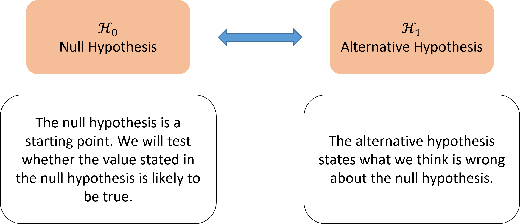

It works like a court: the defendant is **innocent until proven guilty** ($\mathcal{H}_0$: innocent). We reject $\mathcal{H}_0$ only when the evidence is strong. Failing to reject is "not guilty", not "proven innocent".

* **$\alpha$** (often 0.05) is the risk we accept of rejecting a true $\mathcal{H}_0$: a false alarm.
* The **$p$-value** is the probability, **if $\mathcal{H}_0$ were true**, of a result at least as extreme as the one observed.
* Reject $\mathcal{H}_0$ when $p < \alpha$.

Example: $\mathcal{H}_0: \theta = 0.25$ against $\mathcal{H}_1: \theta > 0.25$, with an estimate $\hat\Theta = 0.29$. Standardising with the same standard error as above gives $\hat Z = (\hat\Theta - 0.25)/(\sigma/\sqrt{N}) = 2.92$.

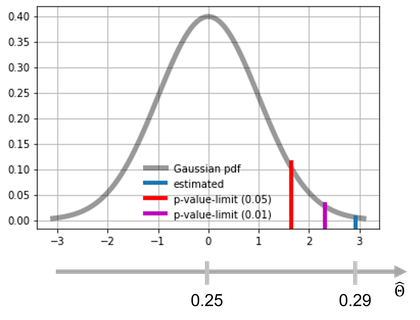

**Predict:** with $\alpha = 0.05$, do we reject $\mathcal{H}_0$?

In [ ]:
z_hat = 2.92
print("critical value z_alpha =", stats.norm.ppf(1 - 0.05))
print("p-value P(Z >= z_hat) =", stats.norm.sf(z_hat))     # sf = 1 - cdf

$\hat Z = 2.92 > 1.645$ and $p \approx 0.002 < 0.05$: both views agree, and we reject $\mathcal{H}_0$ (even at $\alpha = 0.01$).

### Comparing two groups: Welch's t-test

Do two independent groups have different means? $\mathcal{H}_0: \mu_1 = \mu_2$ against $\mathcal{H}_1: \mu_1 \ne \mu_2$.

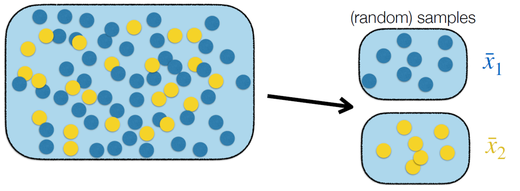

Welch's t-statistic compares the difference of the means with its standard error, **without** assuming equal variances:

$$t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

In SciPy: `stats.ttest_ind(a, b, equal_var=False)`. (The default, `equal_var=True`, is the older **pooled** t-test, which assumes both groups have the same variance.)

**Predict:** do EU member states emit more CO₂ per person than the other European countries? Is the difference "real"?

In [ ]:
# ✍️ Type along: Welch's t-test, EU members vs other European countries (2022)
in_eu = eu22["iso_code"].isin(EU27)

<details><summary>Code from class</summary>

```python
in_eu = eu22["iso_code"].isin(EU27)
members = eu22.loc[in_eu, "co2_per_capita"]
others = eu22.loc[~in_eu, "co2_per_capita"]
print(len(members), round(members.mean(), 2), "|", len(others), round(others.mean(), 2))
print(stats.ttest_ind(members, others, equal_var=False))
```

</details>

EU members average about 6.0 t and the others about 5.3 t, but $p \approx 0.38$: a gap this size would be quite common if there were **no** real difference. We do **not** reject $\mathcal{H}_0$. That is not proof that the means are equal: with 26 and 15 countries and a large spread, the test can only detect big differences.

**Your turn:** compute a 95 % confidence interval for the mean of **each** group. Do the two intervals overlap? Does that fit the $p$-value?

In [ ]:
in_eu = eu22["iso_code"].isin(EU27)
members = eu22.loc[in_eu, "co2_per_capita"]
others = eu22.loc[~in_eu, "co2_per_capita"]
# your code here

<details><summary>Answer</summary>

```python
for name, g in [("EU members", members), ("others", others)]:
    se = g.std(ddof=1) / np.sqrt(len(g))      # pandas .std() already uses ddof=1
    print(f"{name}: {g.mean():.2f}  [{g.mean() - 1.96 * se:.2f}, {g.mean() + 1.96 * se:.2f}]")
# EU members: 6.01 [5.25, 6.77]    others: 5.29 [3.91, 6.68]
```

They overlap a lot, which fits $p \approx 0.38$. With only 15 countries in the second group, the $t$ quantile (`stats.t.ppf(0.975, 14)` ≈ 2.14) would make its interval a little wider. (Overlapping intervals are a rough guide only; the test is the proper check.)

</details>

**Discuss:** a study reports $p = 0.03$. Has it **proven** that $\mathcal{H}_1$ is true?

<details><summary>Answer</summary>

No. $p = 0.03$ means: if $\mathcal{H}_0$ were true, data this extreme would turn up about 3 % of the time. That is evidence against $\mathcal{H}_0$ at $\alpha = 0.05$, not proof. It doesn't give the probability that $\mathcal{H}_1$ is true, and it says nothing about whether the difference is **large** enough to matter (report the estimate and its interval for that). If 20 true null hypotheses are tested, about one will give $p < 0.05$ by chance. And it relies on assumptions such as independent observations.

</details>

### Takeaways: from samples to conclusions

* `scipy.stats` distributions share `.pmf/.pdf`, `.cdf`, `.ppf` (inverse CDF) and `.rvs`.
* An estimator is a random variable; report an estimate **with** its confidence interval: $\hat\Theta \pm \Phi^{-1}(1-\alpha/2)\,s/\sqrt{N}$ (use $t$ for small $N$).
* The width shrinks like $1/\sqrt{N}$: four times the data, half the width.
* Reject $\mathcal{H}_0$ when $p < \alpha$; never "prove" $\mathcal{H}_0$ or $\mathcal{H}_1$. Welch's test compares two means without assuming equal variances.

## Transition to the lab

**You now know** how to compute and simulate probabilities, describe random variables with their distributions, build a confidence interval for a mean and run a two-sample t-test.

**The lab** (`W10_lab_student.ipynb`, two hours) has two parts:
* **Part A · An unfair die:** you build a biased die with the inverse-CDF method, check that simulations converge to the theory, and draw a running 95 % confidence band around the running mean.
* **Part B · Real CO₂ data:** confidence intervals for two regions' CO₂ per person, a simulation check of the formula, a Welch t-test and its interpretation.
* **Challenge:** a chi-square test of whether your die is fair.

## Week 10 takeaways

* Probabilities are long-run frequencies; conditional probability and Bayes update them with information.
* Random variables are described by PMFs/pdfs and CDFs; `scipy.stats` provides the standard ones.
* An estimate without a confidence interval is incomplete; the interval narrows like $1/\sqrt{N}$.
* A $p$-value measures surprise under $\mathcal{H}_0$. It is not the probability that a hypothesis is true.

## Where next

**CMT124 · Week 11, ML/AI 1.** Regression treats the noise in data as a **random variable**, fits a model by an estimator (least squares), and measures fit with variance-based scores such as $R^2$: all of today's ideas.

**CMT309/509.** Confidence intervals and t-tests are the tools to reach for whenever you compare groups or report a summary in your own analyses: always give the interval, not just the number.

Before you leave: rerun this notebook top to bottom and finish any *Your turn* you skipped.

## Optional: explore after class

**More distributions.** Three more from the same family of tools: the **geometric** (`geom`: number of trials until the first success), the **uniform** (`uniform`: every value in a range equally likely) and the **Cauchy** (`cauchy`: very heavy tails, so extreme values are common and the mean is undefined).

| Geometric, p = 0.5 | Uniform on [0, 1] | Cauchy (log scale) |
|---|---|---|
| 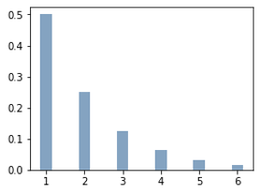 | 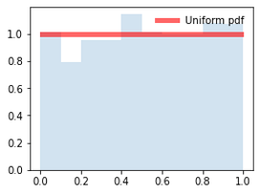 | 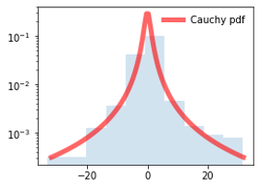 |

**Try it:** take running means of `stats.cauchy.rvs(size=100_000)`. Does the law of large numbers rescue you?

**A one-sample z-test.** Is Europe's typical CO₂ per person in 2022 different from 4.7 t (roughly the world figure)? $\hat Z = (\bar x - 4.7)/(s/\sqrt{n})$, two-sided $p = 2\,\mathbb{P}(Z \ge |\hat Z|)$. `stats.ttest_1samp(x, 4.7)` is the $t$ version.

In [ ]:
z_hat = (x.mean() - 4.7) / (x.std(ddof=1) / np.sqrt(len(x)))
print("z =", round(z_hat, 2), "  two-sided p =", 2 * stats.norm.sf(abs(z_hat)))
print(stats.ttest_1samp(x, 4.7))

## Credits

* CO₂ data: Our World in Data / Global Carbon Project, *CO₂ and Greenhouse Gas Emissions* dataset ([github.com/owid/co2-data](https://github.com/owid/co2-data)), licensed under CC BY 4.0.